In [ ]:
import os
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np
import seaborn as sns
import math
from math import gamma, sin, pi
from powerlaw import Fit
from statsmodels.sandbox.stats.runs import runstest_1samp


In [ ]:
def levy_flight_simulation(n_steps, alpha=1.5, beta=1, theta = [], step_min = 0.1, step_max = 10):
    """
    Simulates a 2D Lévy flight for any alpha>0.
    - 0 < alpha < 2: classical Lévy flight (Mantegna)
    - alpha = 2: Brownian motion
    - alpha > 2: truncated power-law steps
    """

    # Initialize the starting position
    positions = np.zeros((n_steps + 1, 2))

    # Generate random angles for the direction of each step
    if len(theta) == 0:
        theta = 2 * np.pi * np.random.rand(n_steps)

    if alpha == 2:
        # Brownian case
        step_length = np.random.normal(0, np.sqrt(2)*beta, n_steps)
    elif alpha < 2:
        # Mantegna algorithm
        sigma_u = (gamma(1 + alpha) * sin(pi * alpha / 2) /
                   (gamma((1 + alpha) / 2) * alpha * 2**((alpha - 1)/2)))**(1/alpha)
        u = np.random.normal(0, sigma_u, n_steps)
        v = np.random.normal(0, 1, n_steps)
        step_length = beta * u / (np.abs(v)**(1/alpha))
    else:
        # Truncated power-law for alpha > 2 -> Pareto truncate
        mu = alpha + 1  # relate alpha to power-law exponent
        r = np.random.rand(n_steps)
        step_length = (step_min**(1-mu) + r*(step_max**(1-mu)-step_min**(1-mu)))**(1/(1-mu))


    # Update positions based on step lengths and directions
    for i in range(n_steps):
        dx = step_length[i] * np.cos(theta[i])
        dy = step_length[i] * np.sin(theta[i])
        positions[i+1] = positions[i] + np.array([dx, dy])

    return positions


In [ ]:
def alpha_levy_estimate(traj, perct):
    x = traj[:, 0]
    y = traj[:, 1]
    
    angulos = np.arctan2(np.diff(y), np.diff(x))
    umbral_giro = np.percentile(np.minimum(np.abs(np.diff(angulos)), 2*np.pi - np.abs(np.diff(angulos))), perct)#95)
    giros = np.where(np.abs(np.diff(angulos)) > umbral_giro)[0] + 1
    
    # Calcular alpha de Lévy
    longitudes_vuelos = []
    inicio = 0
    for giro in giros:
        longitud = np.sqrt((x[giro] - x[inicio])**2 + (y[giro] - y[inicio])**2)
        longitudes_vuelos.append(longitud)
        inicio = giro
    longitud_final = np.sqrt((x[-1] - x[inicio])**2 + (y[-1] - y[inicio])**2)
    longitudes_vuelos.append(longitud_final)
    
    longitudes_vuelos = np.array(longitudes_vuelos)
    fit = Fit(longitudes_vuelos)#, xmin=np.percentile(distancias, 1)
    mu = fit.power_law.alpha
    return mu - 1, fit.power_law.xmin

In [ ]:
df = pd.read_csv('df.csv')
data = df[["id","t","x","y", "salinidad"]]

/tmp/ipykernel_7016/1113803709.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('df.csv')


In [ ]:
# Centrar posiciones
idx0 = data.groupby("id")["t"].idxmin();
x0 = data.loc[idx0].set_index("id")["x"];
y0 = data.loc[idx0].set_index("id")["y"];

# including centered positions and angles (with respect to the origin)
data.loc[:, "x_c"] = data["x"] - data["id"].map(x0)
data.loc[:, "y_c"] = data["y"] - data["id"].map(y0)
data.loc[:, "angle"] = np.arctan2(data["y"], data["x"])

/tmp/ipykernel_7016/861074527.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:, "x_c"] = data["x"] - data["id"].map(x0)
/tmp/ipykernel_7016/861074527.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[:, "y_c"] = data["y"] - data["id"].map(y0)
/tmp/ipykernel_7016/861074527.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata

## Simulation of Levy flight and estimation of parameter alpha

Calculating best minimal value for power law fit
alpha-hat from power law, 1.7151310159995496


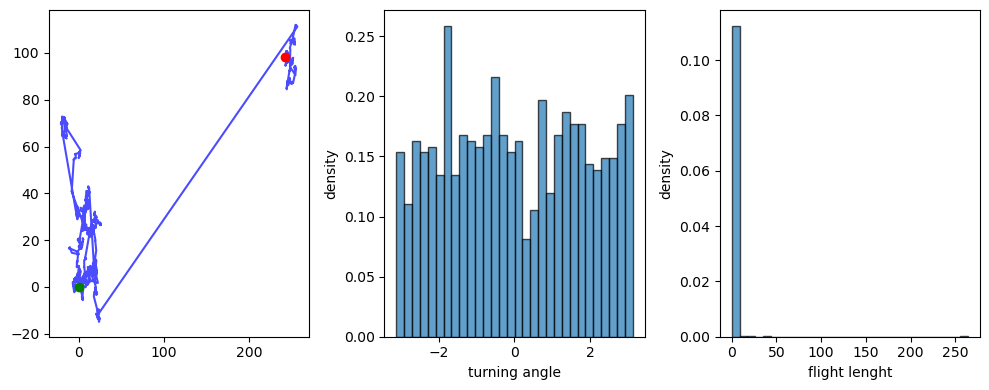

In [ ]:
num_steps = 1000

levy_path = levy_flight_simulation(num_steps, alpha=1.5)

distancias = np.sqrt(np.diff(levy_path[:,0])**2 + np.diff(levy_path[:,1])**2)

# Ajustar distrib de ley de potencia P(X\geq x) = (x/xmin)^{-(mu-1)}, x\geq xmin
fit = Fit(distancias)
mu = fit.power_law.alpha 

print(f"alpha-hat from power law, {mu-1}")


fig = plt.subplots(1, 3, figsize=(10, 4))

plt.subplot(1,3,1)
plt.plot(levy_path[:, 0], levy_path[:, 1], 'b-', alpha=0.7)
plt.plot(levy_path[-1, 0], levy_path[-1, 1], 'ro', label='End Point')
plt.plot(levy_path[0, 0], levy_path[0, 1], 'go', label='Start Point')

plt.subplot(1,3,2)
plt.hist(np.arctan2(np.diff(levy_path[:,1]),np.diff(levy_path[:,0])), bins=30, density=True, alpha=0.7, edgecolor='black');
plt.xlabel("turning angle")
plt.ylabel("density")

plt.subplot(1,3,3)
plt.hist(distancias, bins=30, density=True, alpha=0.7, edgecolor='black');
plt.xlabel("flight lenght")
plt.ylabel("density")

plt.tight_layout()

## Lets estimate alpha from a power law to each one of the selected trajectories

In [ ]:
T = 10000#11.5
trajectories = []
angles_ = []
ids = [192, 59, 77, 79]

for idx in ids:
    trajectories.append(data[(data["id"] == idx) & (data["t"]< T)][["x_c","y_c"]].values)
    angles_.append(data[(data["id"] == idx) & (data["t"]< T)][["angle"]].values)


Calculating best minimal value for power law fit
alpha-hat from power law, 2.43886862386401
Turning angles seems random (no correlation)


Calculating best minimal value for power law fit
alpha-hat from power law, 45.56056664229869
Randomness test for turning angles: p = 0.0000 (SOME FORM CORRELATION IS PRESENT)


Calculating best minimal value for power law fit
alpha-hat from power law, 4.906024754747277
Turning angles seems random (no correlation)


Calculating best minimal value for power law fit
alpha-hat from power law, 3.7170333181018123
Randomness test for turning angles: p = 0.0006 (SOME FORM CORRELATION IS PRESENT)


Values less than or equal to 0 in data. Throwing out 0 or negative values
Values less than or equal to 0 in data. Throwing out 0 or negative values


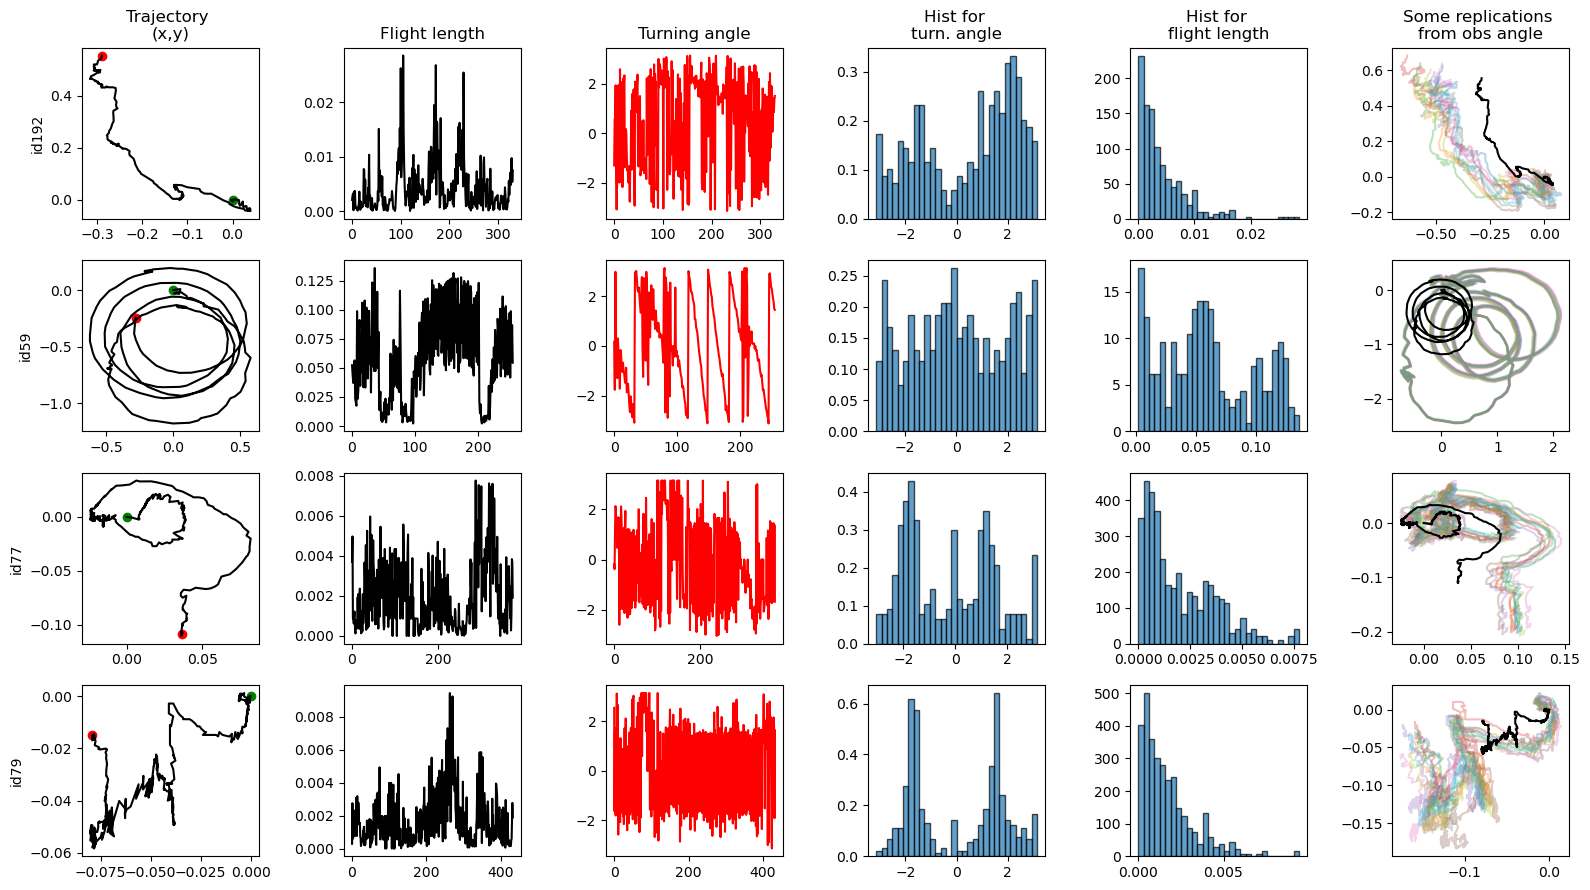

In [ ]:
fig = plt.subplots(4, 6, figsize=(16, 9))

plt.subplot(4,6,1)
plt.title("Trajectory \n(x,y)")
plt.subplot(4,6,2)
#plt.title("Angle wrt \n(0,0)")
plt.title("Flight length")
plt.subplot(4,6,3)
plt.title("Turning angle")
plt.subplot(4,6,4)
plt.title("Hist for \nturn. angle")
plt.subplot(4,6,5)
plt.title("Hist for \nflight length")
plt.subplot(4,6,6)
plt.title("Some replications \nfrom obs angle")

alpha_estim = np.zeros(4)
nb_realiz_levyf = 10

for i in range(4):
    traj = trajectories[i]
    distancias = np.sqrt(np.diff(traj[:,0])**2 + np.diff(traj[:,1])**2)

    plt.subplot(4,6,6*i+1)
    plt.plot(traj[:,0], traj[:,1], 'k')
    plt.scatter(traj[-1,0], traj[-1,1], c = 'r')
    plt.scatter(traj[0,0], traj[0,1], c = 'g')    
    plt.ylabel('id'+str(ids[i]))
    plt.subplot(4,6,6*i+2)
    plt.plot(distancias, 'k')
    #plt.plot(angles_[i], 'k')
    plt.subplot(4,6,6*i+3)
    plt.plot(np.arctan2(np.diff(traj[:,1]),np.diff(traj[:,0])),'r')
    plt.subplot(4,6,6*i+4)
    plt.hist(np.arctan2(np.diff(traj[:,1]),np.diff(traj[:,0])), bins=30, density=True, alpha=0.7, edgecolor='black')
    plt.subplot(4,6,6*i+5)
    plt.hist(distancias, bins=30, density=True, alpha=0.7, edgecolor='black');

    alpha_estim[i], xmin_estim = alpha_levy_estimate(traj, 0)
    xmax_estim = np.percentile(distancias, 100)
    print(f"alpha-hat from power law, {alpha_estim[i]}")

    # Randomness test for turning angles
    stat, p_value = runstest_1samp(np.arctan2(np.diff(traj[:,1]),np.diff(traj[:,0])))
    if p_value < 0.05:
        print(f"Randomness test for turning angles: p = {p_value:.4f} (SOME FORM CORRELATION IS PRESENT)")
    else:
        print("Turning angles seems random (no correlation)")

    xmin_estim = xmin_estim#0.5*xmin_estim

    for j in range(nb_realiz_levyf):
        levy_path = levy_flight_simulation(len(traj)-1, alpha= alpha_estim[i], beta = 1, theta = np.arctan2(np.diff(traj[:,1]),np.diff(traj[:,0])), step_min = xmin_estim, step_max = xmax_estim)
        plt.subplot(4,6,6*i+6)
        plt.plot(levy_path[:, 0], levy_path[:, 1], alpha=0.3)
    plt.plot(traj[:, 0], traj[:, 1], '-k', label='End Point')
    print("\n")

plt.tight_layout()

In [ ]:
candidates_law = ['truncated_power_law', 'exponential', 'lognormal', 'stretched_exponential']
for i in range(4):

    print(f"ID:{ids[i]}")
    
    traj = trajectories[i]
    distancias = np.sqrt(np.diff(traj[:,0])**2 + np.diff(traj[:,1])**2)

    # Compare some distributions against power-law
    fit = Fit(distancias);

    for dist in candidates_law:
        R, p = fit.distribution_compare('power_law', dist);
        
        if R < 0 and p < 0.05:
            print(f"{dist} preferred over power-law")
        elif R > 0 and p < 0.05:
            print(f"Power-law preferred over {dist}")
        else: 
            print(f"No preferences found over {dist}")

    print("\n")



ID:192
Calculating best minimal value for power law fit
No preferences found over truncated_power_law
No preferences found over exponential
No preferences found over lognormal
No preferences found over stretched_exponential


ID:59
Calculating best minimal value for power law fit
No preferences found over truncated_power_law
No preferences found over exponential
lognormal preferred over power-law
No preferences found over stretched_exponential


ID:77
Calculating best minimal value for power law fit


Assuming nested distributions
Assuming nested distributions
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.
Values less than or equal to 0 in data. Throwing out 0 or negative values
Assuming nested distributions


No preferences found over truncated_power_law
No preferences found over exponential
No preferences found over lognormal
No preferences found over stretched_exponential


ID:79
Calculating best minimal value for power law fit
No preferences found over truncated_power_law
No preferences found over exponential
No preferences found over lognormal
No preferences found over stretched_exponential




Values less than or equal to 0 in data. Throwing out 0 or negative values
Assuming nested distributions


En síntesis:

- La distribución de los ángulos entre pasos de las trayectorias 2d no siempre son decorrelacionados y no parecen ser uniformes. 
- Por su parte, la distribución de las longitudes entre puntos de la trayectoria parece ser leyes de potencia (aunque para la que es espiral no parece tanto). Al hacer pruebas power-law vs distribuciones similares (exponential, lognormal, weibull) no se prefieren realmente ante una power-law, pero tampoco es que se prefiera la power-law frente a estas (al menos haciendo la prueba con el clásico nivel de confianza del 95%).
- Ajustando la power-law, la potencia es muy alta para lo que se espera del vuelo de Lèvy con 0<alpha<2 (y el algoritmo para simularlo está diseñado sólo para estos valores). Sin embargo, ajustando una ley de potencia truncada, y usando los ANGULOS observados se ven cosas razonables. 
- Con xmin_estim~ xmin_estim/2 de hecho la escala de la trayectoria se parece más aún, pero ya esto es manipular subjetivamente.

Podríamos preguntarnos si la estimación de estos xmin y estos alpha si muestran más diferencias en función de la salinidad